# Quantiva — retail exploration

Analyze real UCI Online Retail data at line, invoice, customer, and calendar grain.
Run `quantiva download`, `quantiva prepare`, and `quantiva database` first.
**Scope:** Phase 2 only. Gross eligible sales include anonymous purchases and
nonstandard codes. Cancellations are separate signed movements; no net accounting
or confirmed physical-return claim is made. Definitions: `reports/kpi_specification.md`.
Each run verifies source provenance and independently reconciles SQL and pandas.


In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from quantiva.analysis_report import collect_analysis
from quantiva.config import Settings
from quantiva.visualization import create_figures

if os.environ.get("QUANTIVA_KERNEL_EXECUTABLE"):
    assert (
        Path(sys.executable).resolve() == Path(os.environ["QUANTIVA_KERNEL_EXECUTABLE"]).resolve()
    )
root = Path.cwd()
while not (root / "PROJECT_SPECIFICATION.md").exists():
    if root == root.parent:
        raise RuntimeError("Run within the Quantiva repository")
    root = root.parent
a = collect_analysis(Settings.from_environment())
s = a["summary"]
assert a["reconciliation"]["passed"].all()
figures = root / "reports" / "figures"
create_figures(a, figures)
print("Python", sys.version.split()[0], "— independent reconciliation passed")

Python 3.11.9 — independent reconciliation passed


## Revenue and observation coverage

In [2]:
display(pd.DataFrame([s["kpis"]]).T.rename(columns={0: "value"}))
display(a["monthly"])
display(
    Markdown(
        f"Gross eligible sales are **£{s['kpis']['gross_revenue_gbp']:,.2f}** from "
        f"**{s['kpis']['completed_orders']:,} invoices**, with AOV "
        f"**£{s['kpis']['aov_gbp']:,.2f}**. "
        "Invoice counts use distinct codes; multiple lines do not create extra orders. "
        "Monthly growth excludes incomplete months and compares adjacent full periods only."
    )
)
display(pd.DataFrame({"missing_date": s["coverage"]["no_transaction_dates"]}))
display(a["weekdays"])
display(
    Markdown(
        f"{s['coverage']['observed_days']} of {s['coverage']['calendar_days']} calendar dates "
        "contain ledger activity. The final date is partial; missing dates are zero recorded "
        "activity, "
        "not proof of zero demand. Weekday comparisons use all interior calendar dates."
    )
)

,value
gross_revenue_gbp,1.064211e+07
completed_orders,1.996000e+04
aov_gbp,5.331719e+02
units_sold,5.572420e+06
identifiable_customers,4.338000e+03
identifiable_revenue_gbp,8.887209e+06
revenue_per_identifiable_customer_gbp,2.048688e+03
repeat_customers,2.845000e+03
repeat_purchase_rate,6.558322e-01


,month,revenue_gbp,complete_month,growth_pct
0,2010-12,821452.730,True,NaN
1,2011-01,689811.610,True,-16.025404
2,2011-02,522545.560,True,-24.248077
3,2011-03,716215.260,True,37.062740
4,2011-04,536968.491,True,-25.026941
5,2011-05,769296.610,True,43.266620
6,2011-06,760547.010,True,-1.137351
7,2011-07,718076.121,True,-5.584256
8,2011-08,757841.380,True,5.537750
9,2011-09,1056435.192,True,39.400568


Gross eligible sales are **£10,642,110.80** from **19,960 invoices**, with AOV **£533.17**. Invoice counts use distinct codes; multiple lines do not create extra orders. Monthly growth excludes incomplete months and compares adjacent full periods only.

,missing_date
0,2010-12-04
1,2010-12-11
2,2010-12-18
3,2010-12-24
4,2010-12-25
...,...
64,2011-11-05
65,2011-11-12
66,2011-11-19
67,2011-11-26


,calendar_days,observed_days,mean_calendar_revenue_gbp,median_calendar_revenue_gbp
weekday,,,,
Monday,53,47,33505.322094,29262.720
Tuesday,53,52,41050.953038,35545.830
Wednesday,53,52,33741.463962,28068.200
Thursday,54,53,40727.640185,36431.965
Friday,53,49,30878.670019,28107.650
Saturday,53,0,0.000000,0.000
Sunday,53,50,15222.467566,12156.570


305 of 374 calendar dates contain ledger activity. The final date is partial; missing dates are zero recorded activity, not proof of zero demand. Weekday comparisons use all interior calendar dates.

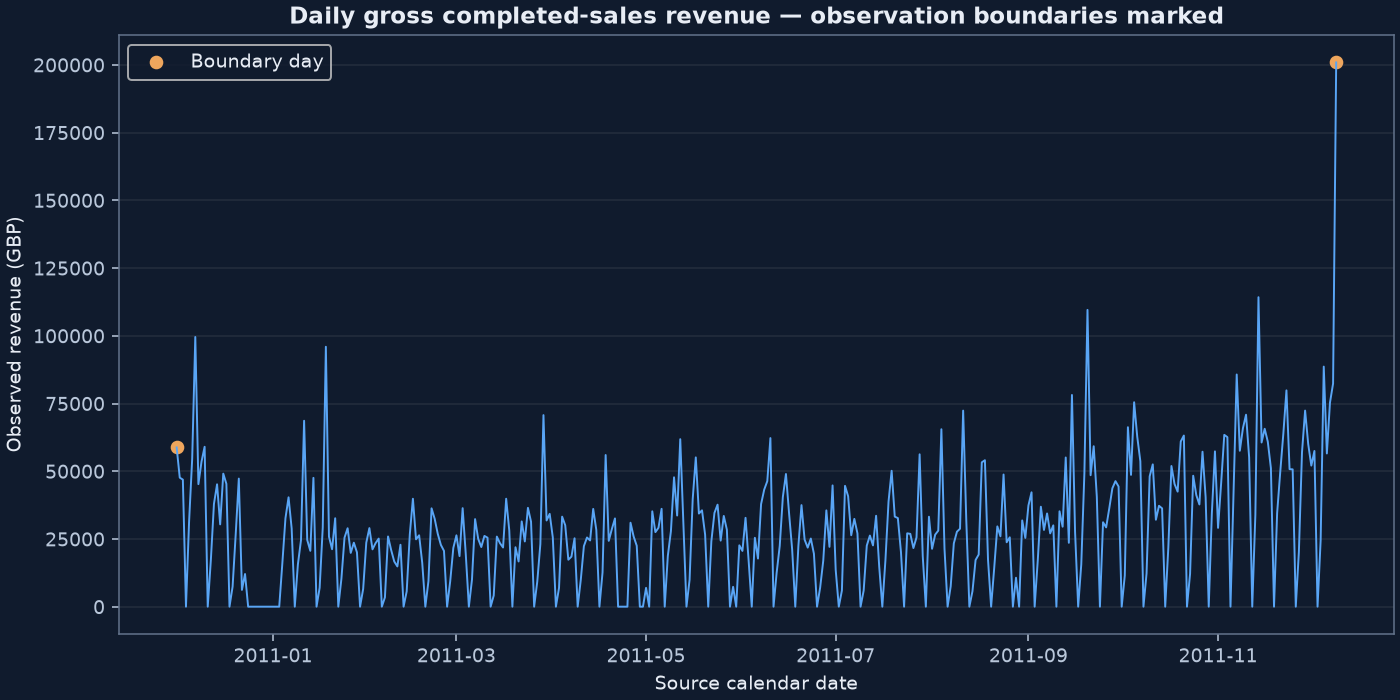

In [3]:
display(Image(filename=str(figures / "daily_revenue.png")))

**Interpretation.** Large daily spikes coexist with dates without records. Boundary days are marked; the final day ends at 12:50. Treat the curve as observed sales, not a complete measure of demand.

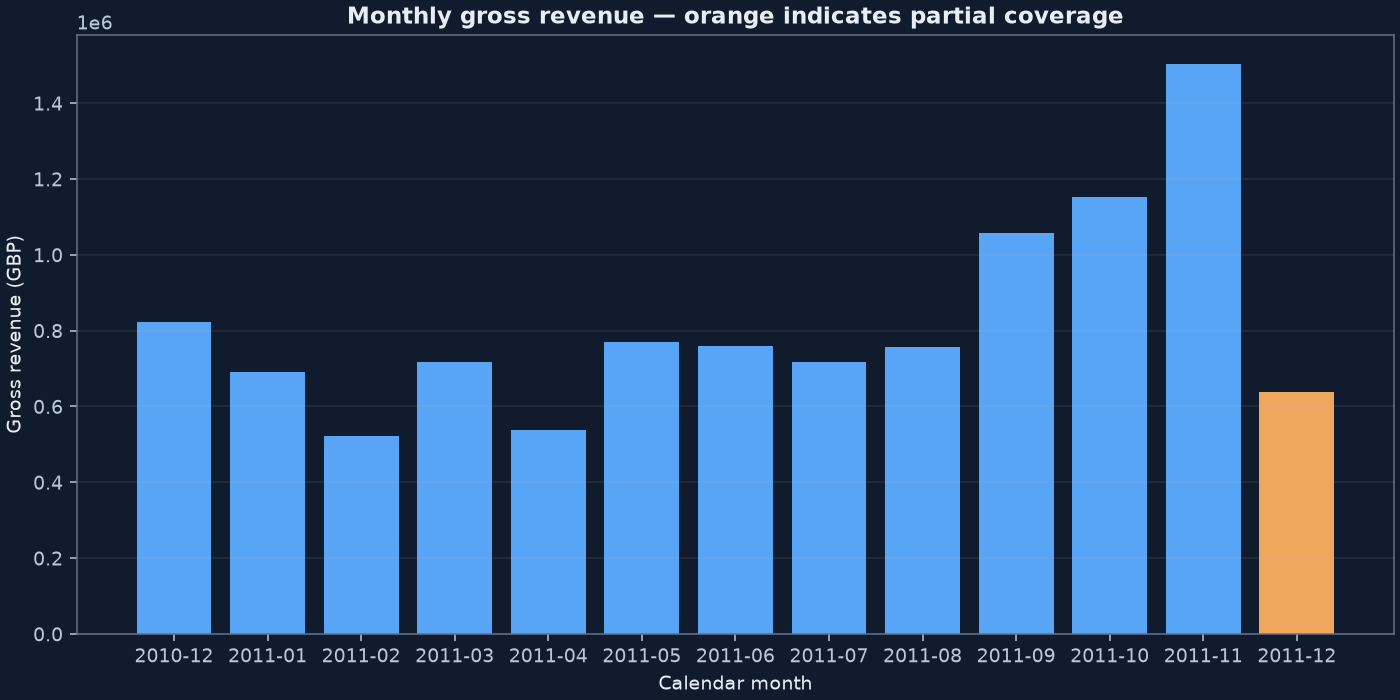

In [4]:
display(Image(filename=str(figures / "monthly_revenue.png")))

**Interpretation.** Orange marks truncated coverage. December 2011 is not comparable with a full December or November. Full-month changes are descriptive; this short series cannot establish annual seasonality.

## Products, names, and revenue concentration

In [5]:
display(a["products"].head(10))
display(a["queries"]["top_product_units"].head(10))
display(a["products"].sort_values(["units", "stock_code"]).head(10))
display(a["product_behavior"].sort_values("distinct_descriptions", ascending=False).head(10))
display(a["nonstandard"])
display(
    Markdown(
        f"Top ten codes contribute **{s['concentration']['top_10_products_share_pct']:.2f}%** "
        f"of revenue. **{s['coverage']['products_with_multiple_descriptions']}** codes have "
        f"multiple "
        "descriptions. StockCode is the key; names are historical labels. Lowest positive-volume "
        "codes are slow-moving in this window, not proven unsuccessful products. Nonstandard "
        "syntax "
        "is an investigation heuristic and does not remove codes from KPIs."
    )
)

,stock_code,display_description,revenue_gbp,units,orders,revenue_rank,revenue_share_pct
0,DOT,DOTCOM POSTAGE,206248.77,706,706,1,1.938044
1,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,2,1.636485
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,3,1.583047
3,85123A,CREAM HANGING HEART T-LIGHT HOLDER,104462.75,37641,2198,4,0.981598
4,47566,PARTY BUNTING,99445.23,18283,1685,5,0.934450
5,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,6,0.884785
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,7,0.767713
7,POST,POSTAGE,78101.88,3150,1126,8,0.733895
8,M,Manual,77750.27,6984,289,9,0.730591
9,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,10,0.628353


,stock_code,units,units_rank
0,23843,80995,1
1,23166,78033,2
2,22197,56898,3
3,84077,54951,4
4,85099B,48371,5
5,85123A,37641,6
6,21212,36396,7
7,84879,36362,8
8,23084,30739,9
9,22492,26633,10


,stock_code,display_description,revenue_gbp,units,orders,revenue_rank,revenue_share_pct
3841,20703,BLUE PADDED SOFT MOBILE,4.25,1,1,3673,0.000040
3893,20860,GOLD COSMETICS BAG WITH BUTTERFLY,2.10,1,1,3706,0.000020
3907,21009,ETCHED GLASS STAR TREE DECORATION,1.25,1,1,3713,0.000012
3614,21120,*Boombox Ipod Classic,16.98,1,1,3529,0.000160
3865,21160,KEEP OUT GIRLS DOOR HANGER,3.36,1,1,3689,0.000032
3466,21310,CAPIZ CHANDELIER,29.95,1,1,3413,0.000281
3755,21410,COUNTRY COTTAGE DOORSTOP GREEN,8.47,1,1,3626,0.000080
3894,21414,SCALLOP SHELL SOAP DISH,2.10,1,1,3706,0.000020
3900,21491,SET OF THREE VINTAGE GIFT WRAPS,1.95,1,1,3709,0.000018
3813,21839,MUMMY MOUSE RED GINGHAM RIBBON,5.45,1,1,3658,0.000051


,stock_code,distinct_descriptions,nonstandard_code_candidate
173,20713,8,False
1982,23084,7,False
871,21830,6,False
3593,85175,6,False
429,21181,5,False
2864,72807A,5,False
2025,23131,5,False
2224,23343,5,False
3590,85172,5,False
2966,82583,4,False


,stock_code,display_description,revenue_gbp,units,orders,revenue_rank,revenue_share_pct
0,DOT,DOTCOM POSTAGE,206248.770,706,706,1,1.938044e+00
7,POST,POSTAGE,78101.880,3150,1126,8,7.338946e-01
8,M,Manual,77750.270,6984,289,9,7.305907e-01
151,AMAZONFEE,AMAZON FEE,13761.090,2,2,152,1.293079e-01
204,B,Adjust bad debt,11062.060,1,1,205,1.039461e-01
351,C2,CARRIAGE,7051.000,142,141,352,6.625565e-02
2791,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,175.530,7,7,2780,1.649391e-03
2812,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00,167.560,4,4,2801,1.574500e-03
2814,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,167.050,10,9,2803,1.569707e-03
2820,BANK CHARGES,Bank Charges,165.001,12,11,2809,1.550454e-03


Top ten codes contribute **10.82%** of revenue. **647** codes have multiple descriptions. StockCode is the key; names are historical labels. Lowest positive-volume codes are slow-moving in this window, not proven unsuccessful products. Nonstandard syntax is an investigation heuristic and does not remove codes from KPIs.

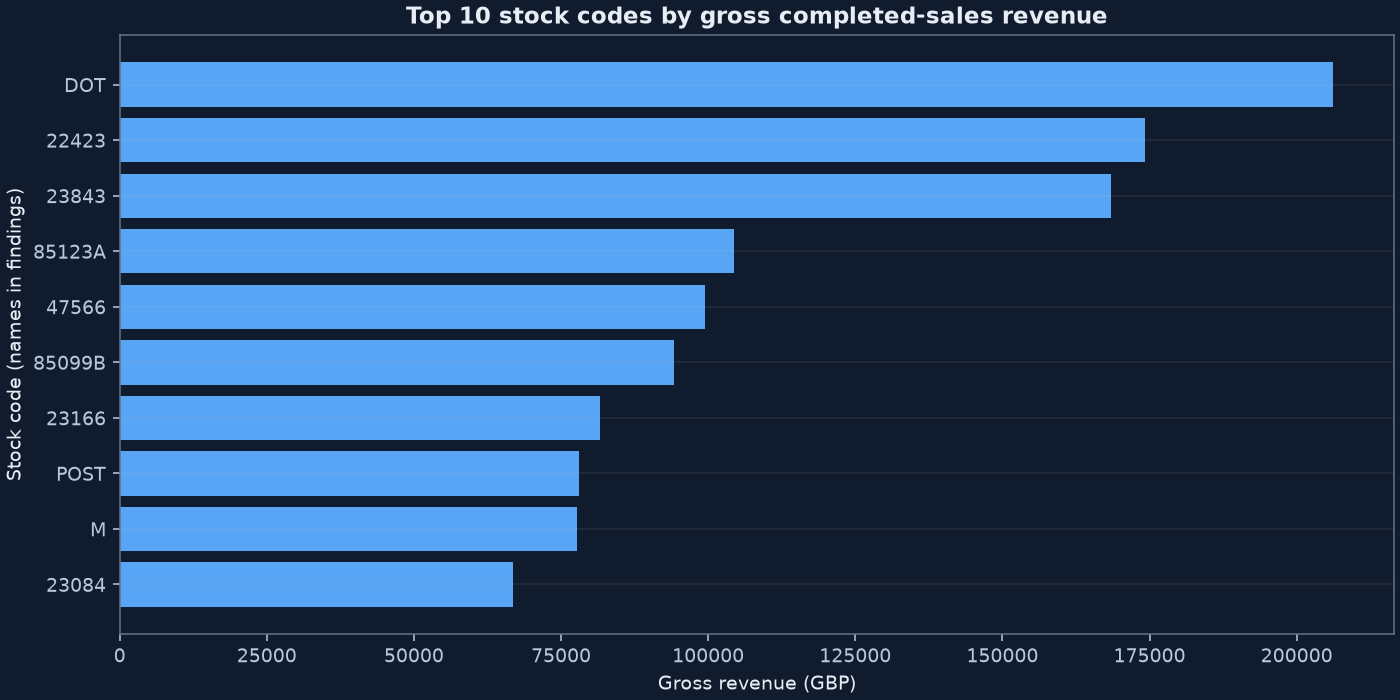

In [6]:
display(Image(filename=str(figures / "top_products.png")))

**Interpretation.** These are gross code-level contributions. Large bulk orders and service codes may affect rankings; the full product table retains units, invoice counts, and names for interpretation.

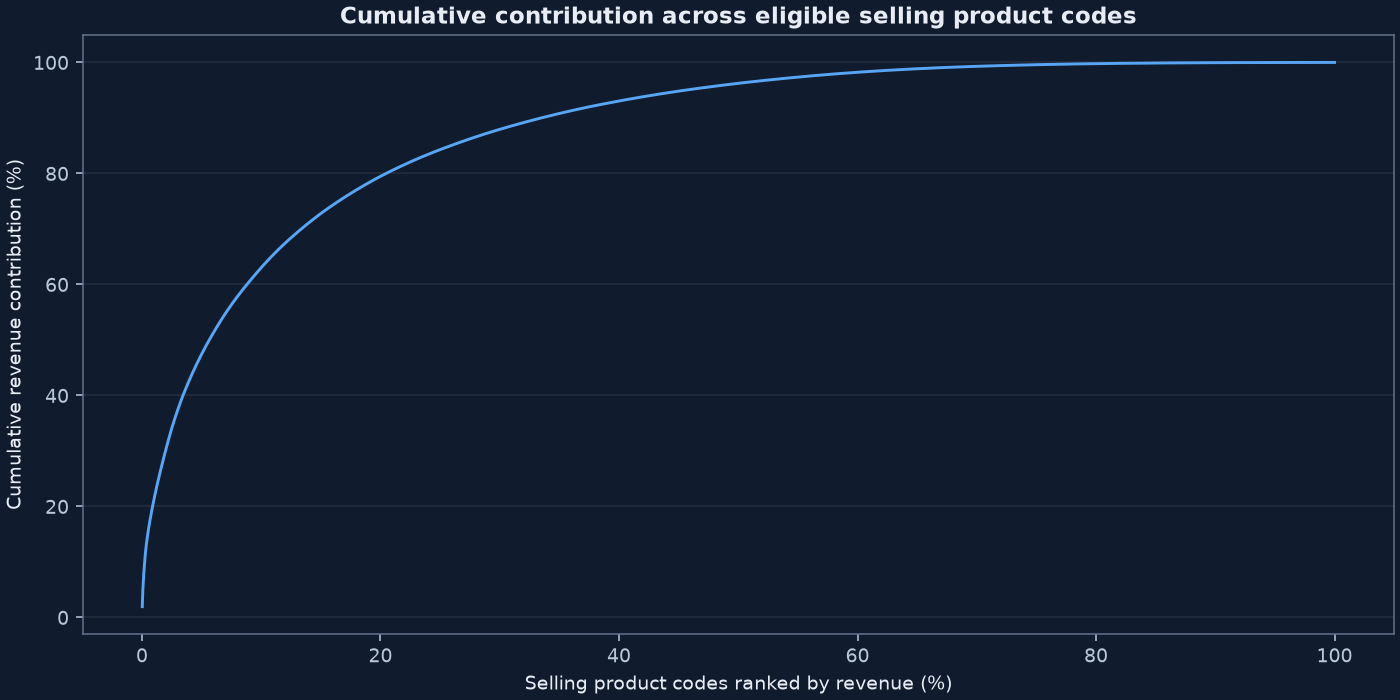

In [7]:
display(Image(filename=str(figures / "product_concentration.png")))

**Interpretation.** The cumulative curve includes every selling code. A steep early rise shows concentration and explains why a small number of codes can materially influence total revenue.

## Customers and geography

In [8]:
display(
    a["customers"]["frequency"].value_counts().sort_index().rename("customers").to_frame().head(20)
)
display(a["customers"][["frequency", "spending_gbp"]].head(10))
display(a["countries"])
display(
    Markdown(
        f"Within-period repeat purchasing is **{s['kpis']['repeat_purchase_rate']:.2%}** "
        "of identifiable purchasers with at least two distinct invoices. "
        f"Anonymous revenue is **{s['concentration']['anonymous_revenue_share_pct']:.2f}%** of "
        f"gross sales, "
        "so identified-customer conclusions need not represent every shopper. "
        f"The UK contributes **{s['concentration']['uk_revenue_share_pct']:.2f}%** of revenue. "
        "Country comparisons describe one retailer's customer mix, not national market demand."
    )
)

,customers
frequency,
1,1493
2,835
3,508
4,388
5,242
6,172
7,143
8,98
9,68


,frequency,spending_gbp
0,73,280206.02
1,60,259657.30
2,46,194390.79
3,2,168472.50
4,201,143711.17
5,21,124914.53
6,55,117210.08
7,31,91062.38
8,63,80850.84
9,1,77183.60


,country,revenue_gbp,orders,sale_lines,revenue_share_pct
0,United Kingdom,9001744.094,18019,479985,84.586078
1,Netherlands,285446.340,94,2359,2.682234
2,EIRE,283140.520,288,7879,2.660567
3,Germany,228678.400,457,9025,2.148807
4,France,209625.370,392,8392,1.969772
5,Australia,138453.810,57,1181,1.301000
6,Spain,61558.560,90,2479,0.578443
7,Switzerland,57067.600,54,1958,0.536243
8,Belgium,41196.340,98,2031,0.387107
9,Sweden,38367.830,36,450,0.360528


Within-period repeat purchasing is **65.58%** of identifiable purchasers with at least two distinct invoices. Anonymous revenue is **16.49%** of gross sales, so identified-customer conclusions need not represent every shopper. The UK contributes **84.59%** of revenue. Country comparisons describe one retailer's customer mix, not national market demand.

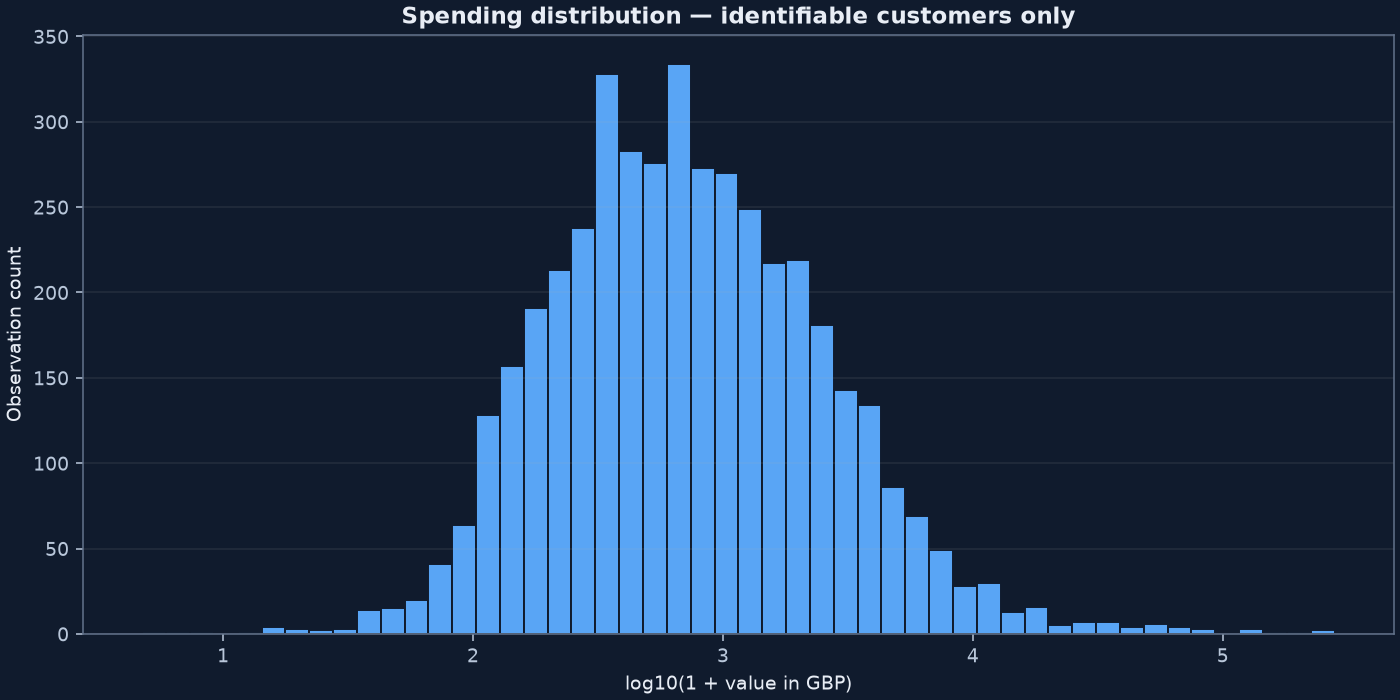

In [9]:
display(Image(filename=str(figures / "customer_spending.png")))

**Interpretation.** log10(1 + spending in GBP) displays the long tail while retaining all known purchasers. No customer is invented for anonymous records; those sales remain in overall revenue.

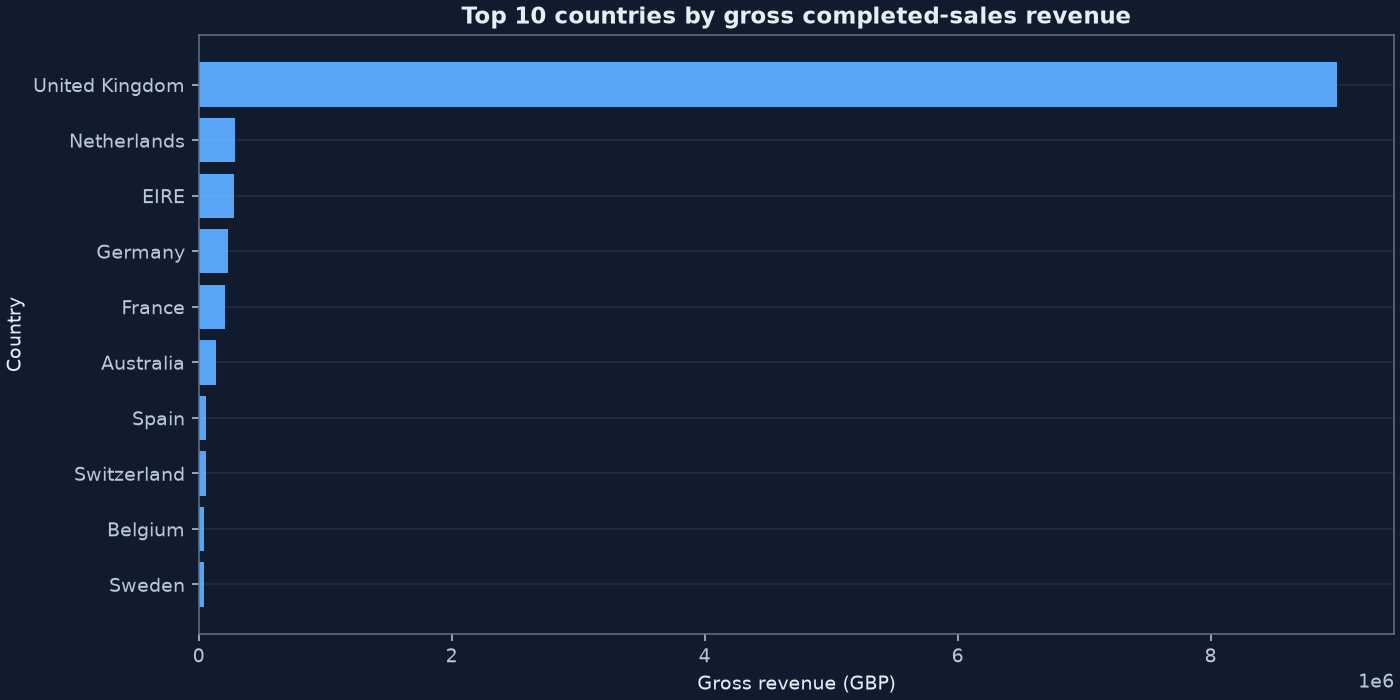

In [10]:
display(Image(filename=str(figures / "country_revenue.png")))

**Interpretation.** The UK dominates this retailer's recorded revenue. The ranking is descriptive and does not establish that geography causes greater spending.

## Audit sensitivity and extreme records

In [11]:
display(a["sensitivity"])
display(a["queries"]["adjustments"])
display(
    a["extreme_groups"].sort_values("Quantity", key=lambda v: v.abs(), ascending=False).head(20)
)
display(
    a["ledger"].nlargest(10, "UnitPrice")[
        ["StockCode", "Description", "Quantity", "UnitPrice", "transaction_type"]
    ]
)
audit = pd.read_parquet(Settings.from_environment().processed_dir / "exclusions.parquet")
display(
    audit.loc[
        ~audit["exclusion_reason"].eq("exact_duplicate"),
        ["StockCode", "Description", "Quantity", "UnitPrice", "exclusion_reason"],
    ]
)
display(
    Markdown(
        "Duplicates can be identical legitimate lines or extraction repeats; no line key resolves "
        "that ambiguity. Restoring eligible duplicates changes amounts and units but may not "
        "change distinct "
        "orders. Extreme positive and negative quantities suggest reversal candidates, without "
        "proving matched "
        "returns. Negative-price bad-debt entries remain quarantined; stock corrections are not "
        "customer returns."
    )
)

,metric,deduplicated,duplicates_retained,difference,change_pct
0,gross_revenue_gbp,1.064211e+07,1.066668e+07,24573.740000,0.230910
1,completed_orders,1.996000e+04,1.996000e+04,0.000000,0.000000
2,aov_gbp,5.331719e+02,5.344030e+02,1.231149,0.230910
3,units_sold,5.572420e+06,5.588376e+06,15956.000000,0.286339


,transaction_type,lines,signed_amount_gbp
0,cancellation,9251,-8.939797e+05
1,completed_sale,524878,1.064211e+07
2,stock_adjustment_candidate,1336,0.000000e+00
3,zero_value,1174,0.000000e+00


,StockCode,Quantity,transaction_type,lines,signed_amount_gbp
358,23843,80995,completed_sale,1,168469.60
357,23843,-80995,cancellation,1,-168469.60
298,23166,-74215,cancellation,1,-77183.60
299,23166,74215,completed_sale,1,77183.60
436,84826,12540,zero_value,1,0.00
279,23005,-9600,stock_adjustment_candidate,2,0.00
427,84347,-9360,cancellation,1,-280.80
278,23003,-9058,stock_adjustment_candidate,1,0.00
366,37413,5568,zero_value,1,0.00
388,72140F,-5368,stock_adjustment_candidate,1,0.00


,StockCode,Description,Quantity,UnitPrice,transaction_type
220826,M,Manual,-1,38970.00,cancellation
519495,AMAZONFEE,AMAZON FEE,-1,17836.46,cancellation
43193,AMAZONFEE,AMAZON FEE,-1,16888.02,cancellation
43194,AMAZONFEE,AMAZON FEE,-1,16453.71,cancellation
14756,AMAZONFEE,AMAZON FEE,-1,13541.33,cancellation
14757,AMAZONFEE,AMAZON FEE,1,13541.33,completed_sale
16087,AMAZONFEE,AMAZON FEE,-1,13541.33,cancellation
15972,AMAZONFEE,AMAZON FEE,-1,13474.79,cancellation
519494,AMAZONFEE,AMAZON FEE,-1,11586.50,cancellation
297645,B,Adjust bad debt,1,11062.06,completed_sale


,StockCode,Description,Quantity,UnitPrice,exclusion_reason
2337,B,Adjust bad debt,1,-11062.06,invalid_price
2338,B,Adjust bad debt,1,-11062.06,invalid_price


Duplicates can be identical legitimate lines or extraction repeats; no line key resolves that ambiguity. Restoring eligible duplicates changes amounts and units but may not change distinct orders. Extreme positive and negative quantities suggest reversal candidates, without proving matched returns. Negative-price bad-debt entries remain quarantined; stock corrections are not customer returns.

## Phase 3 recommendations

Investigate the missing-date schedule and decide whether calendar zeros mean closed days,
missing collection, or no transactions. Exclude or separately flag the final partial day.
Choose whether forecasting includes service/charge codes and exceptionally reversed bulk
orders, documenting sensitivity. Begin with naive/weekly baselines and chronological
validation; never use random time-series splits. No models are implemented here.
